# ApexPlanet Internship – Task 2
## SQL & Data Extraction
This notebook demonstrates SQLite + Python + Pandas integration.

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd

ROOT = Path.cwd()
DB = ROOT / 'database' / 'sales.db'
if not DB.exists():
    # If the notebook is launched from notebooks/, use the parent folder.
    ROOT = Path.cwd().parent
    DB = ROOT / 'database' / 'sales.db'

conn = sqlite3.connect(DB)
print('Database:', DB)

Database: c:\Users\Vinay Kumar\OneDrive\Desktop\apexplanet_task2_sql_data_extraction-3\apexplanet_task2_sql_data_extraction\database\sales.db


## 1. Load SQL query into a DataFrame

In [2]:
query = '''
SELECT category,
       ROUND(SUM(revenue), 2) AS revenue,
       ROUND(SUM(profit), 2) AS profit,
       SUM(quantity) AS units_sold
FROM sales_detail
WHERE status = 'Delivered'
GROUP BY category
ORDER BY revenue DESC;
'''
category_df = pd.read_sql_query(query, conn)
category_df

,category,revenue,profit,units_sold
0,Electronics,794000.0,249000.0,23
1,Furniture,240000.0,85500.0,13
2,Audio,133000.0,55800.0,17
3,Accessories,86500.0,39600.0,35


## 2. Monthly sales trend

In [10]:
import sqlite3
import pandas as pd
from pathlib import Path

# Find the project folder
ROOT = Path.cwd()

# If notebook is running from the notebooks folder
if (ROOT / "database" / "sales.db").exists():
    DB = ROOT / "database" / "sales.db"
else:
    DB = ROOT.parent / "database" / "sales.db"

# Open a fresh database connection
conn = sqlite3.connect(DB)

monthly_query = """
SELECT 
    strftime('%Y-%m', order_date) AS month,
    ROUND(SUM(revenue), 2) AS revenue
FROM sales_detail
WHERE status = 'Delivered'
GROUP BY month
ORDER BY month;
"""

monthly_df = pd.read_sql_query(monthly_query, conn)

monthly_df

,month,revenue
0,2025-01,176500.0
1,2025-02,204700.0
2,2025-03,174000.0
3,2025-04,150400.0
4,2025-05,214800.0
5,2025-06,127000.0
6,2025-07,47600.0
7,2025-08,158500.0


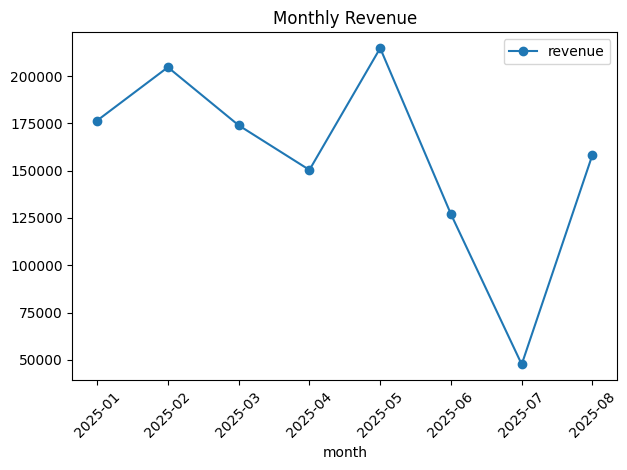

In [4]:
import matplotlib.pyplot as plt
monthly_df.plot(x='month', y='revenue', kind='line', marker='o', title='Monthly Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Top customers

In [5]:
top_customers = pd.read_sql_query('''
SELECT customer_name, ROUND(SUM(revenue),2) AS total_revenue
FROM sales_detail
WHERE status = 'Delivered'
GROUP BY customer_id, customer_name
ORDER BY total_revenue DESC
LIMIT 10;
''', conn)
top_customers

,customer_name,total_revenue
0,Arjun Kumar,284400.0
1,Vikram Singh,173500.0
2,Priya Reddy,151000.0
3,Ananya Das,129100.0
4,Sneha Patel,100000.0
5,Isha Mehta,99500.0
6,Rahul Sharma,87500.0
7,Divya Iyer,61000.0
8,Kiran Rao,55400.0
9,Meera Nair,47500.0


## 4. Business insight
The SQL layer performs joins, aggregation, subqueries, CTEs and window functions. Pandas receives the SQL result as a DataFrame for further analysis and visualization.

In [7]:
conn.close()